# 10. NLP: Text to Sparse Features / NLP: Metinden Sparse Özniteliklere

**English theory:** [Classification](../Classification.md) · **Türkçe teori:** [Sınıflandırma](../Classification.tr.md) · [Notebook index / dizin](../README.md)

Turn English review sentences into count and TF-IDF features. Inspect CSR storage, compare six pipelines with training-only CV, and evaluate one selected sentiment classifier on a held-out set.

**Türkçe:** Metnin sayısal temsili, sparse matris, TF-IDF ve model karşılaştırmasını gerçek yorumlarla çalıştırıyoruz. Hedef yorumun duygu etiketidir: `0=negative`, `1=positive`. Önceki %48 sonucu farklı bir veri ve hedeften bildirildi; buradaki skor onun iyileştirildiğinin kanıtı değildir.

Run **Restart Kernel → Run All** to reproduce every output. Each notebook starts from raw local data and has no dependency on another notebook's variables. Saved tables and figures are actual executed outputs.

**Türkçe:** Sonuçları yeniden üretmek için çekirdeği yeniden başlatıp bütün hücreleri sırayla çalıştırın. Veri dosyaları repoda bulunur; başka bir notebook'un önceden çalıştırılması gerekmez.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, JSON

# Works when launched from this folder, Classification/, or the repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
CLASSIFICATION_DIR = next(
    folder for base in candidates for folder in (base, base / "Classification")
    if (folder / "Classification.md").is_file()
    and (folder / "datasets" / "data.csv").is_file()
)
SEED = 42
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 12)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "SciPy": scipy.__version__,
            "scikit-learn": sklearn.__version__, "Matplotlib": matplotlib.__version__}
display(pd.Series(versions, name="Environment"))

Python          3.10.11
NumPy            1.26.4
pandas            2.3.3
SciPy            1.13.1
scikit-learn      1.7.2
Matplotlib       3.10.9
Name: Environment, dtype: object

In [2]:
import hashlib
import re
import unicodedata
from scipy import sparse
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import LinearSVC

ROOT = CLASSIFICATION_DIR

## Parse and audit the local data / Yerel veriyi oku ve denetle

UCI **Sentiment Labelled Sentences** has 1,000 sentences each from Amazon, IMDb and Yelp, with a sentiment label after the final tab. Two IMDb records span physical lines: accumulate lines until a terminal tab-label appears rather than silently dropping fragments. Normalize keys for duplicate detection, remove conflicting duplicates if any, then deduplicate **before splitting**. We do not remove negation words such as `not`.

The raw files and their [license/source record](../datasets/nlp_sentiment/README.md) are in the repository. File hashes in the audit identify the exact inputs. This short English-review benchmark does not establish performance on Turkish text or a different domain.

**Türkçe:** Satır sayısı ile kayıt sayısı aynı olmayabilir. Etiketi sonda yakalayıp bölünmüş kayıtları birleştiriyoruz. Aynı metin eğitim ve teste dağılmasın diye metin anahtarlarıyla tekrarları ayıklıyoruz.

In [3]:
def text_key(text):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", text).casefold()).strip()

def load_sentiment():
    rows, hashes = [], {}
    folder = ROOT / "datasets" / "nlp_sentiment"
    for source in ["amazon_cells", "imdb", "yelp"]:
        p = folder / f"{source}_labelled.txt"
        raw = p.read_bytes()
        hashes[p.name] = hashlib.sha256(raw).hexdigest()
        pending = []
        for line in raw.decode("utf-8").splitlines():
            if not line.strip():
                continue
            pending.append(line)
            # Two IMDb records wrap across physical lines; the terminal tab +
            # label delimits a record. Do not silently discard these fragments.
            if not re.search(r"\t[01]\s*$", line):
                continue
            text, label = " ".join(pending).rsplit("\t", 1)
            pending = []
            assert label.strip() in {"0", "1"}
            rows.append({"text": text.strip(), "label": int(label), "source": source})
        assert not pending, f"Unterminated record in {p.name}"
    frame = pd.DataFrame(rows)
    assert len(frame) == 3000
    frame["key"] = frame.text.map(text_key)
    raw_n = len(frame)
    conflicts = frame.groupby("key").label.nunique()
    conflicting_keys = set(conflicts[conflicts > 1].index)
    conflict_rows = frame.key.isin(conflicting_keys)
    n_conflicts = int(conflict_rows.sum())
    clean = frame.loc[~conflict_rows & frame.key.ne("")].drop_duplicates("key").reset_index(drop=True)
    info = {"raw_rows": raw_n, "conflicting_rows_removed": n_conflicts,
            "duplicate_rows_removed": int(raw_n - n_conflicts - len(clean)),
            "clean_rows": len(clean), "source_sha256": hashes}
    return clean, info

frame, audit = load_sentiment()
display(JSON(audit, expanded=True))
display(pd.crosstab(frame.source, frame.label).rename(columns={0: "negative", 1: "positive"}))
display(frame[["text", "label", "source"]].head())

<IPython.core.display.JSON object>

label,negative,positive
source,,
amazon_cells,496,491
imdb,498,498
yelp,497,499


,text,label,source
0,So there is no way for me to plug it in here i...,0,amazon_cells
1,"Good case, Excellent value.",1,amazon_cells
2,Great for the jawbone.,1,amazon_cells
3,Tied to charger for conversations lasting more...,0,amazon_cells
4,The mic is great.,1,amazon_cells


## Bag of words and CSR / Kelime sayımları ve CSR

A document–term matrix has one row per document and one column per vocabulary item. Most entries are zero. CSR stores only `data` (nonzero values), `indices` (their column numbers) and `indptr` (where each row starts in those arrays).

For row $i$, use the slice `indptr[i]:indptr[i+1]`; the final `indptr` value equals `nnz`. CSR column indices are not guaranteed sorted after every operation, so we explicitly sort this teaching example. Dense conversion is safe for this **3×4 toy matrix**, not for arbitrary corpora.

**Türkçe:** Boş hücreleri saklamak yerine yalnız sıfır olmayan değerleri ve konumlarını tutarız. `indptr` uzunluğu satır sayısından bir fazladır; satırın başlangıç/bitişini verir.

,bad,good,movie,not
good movie,0,1,1,0
not good movie,0,1,1,1
good good bad,1,2,0,0


Vocabulary: {'bad': 0, 'good': 1, 'movie': 2, 'not': 3}
data   = [1 1 1 1 1 1 2]
indices= [1 2 1 2 3 0 1]
indptr = [0 2 5 7]


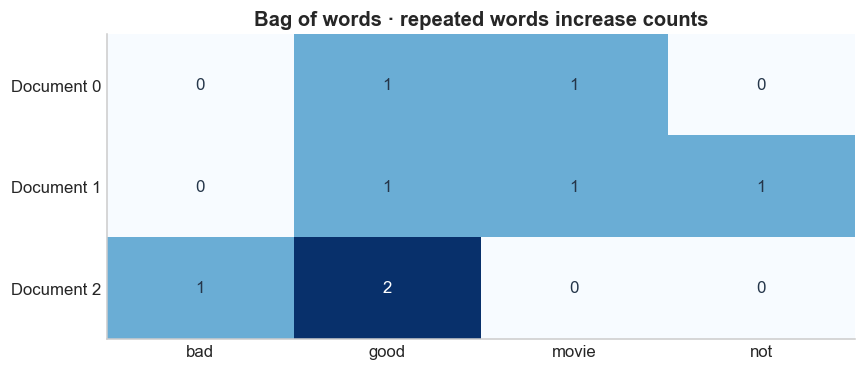

In [4]:
toy_documents = ["good movie", "not good movie", "good good bad"]
count_vectorizer = CountVectorizer()
counts = count_vectorizer.fit_transform(toy_documents).tocsr()
counts.sort_indices()
words = count_vectorizer.get_feature_names_out()
display(pd.DataFrame(counts.toarray(), columns=words, index=toy_documents))
print("Vocabulary:", dict(zip(words, range(len(words)))))
print("data   =", counts.data)
print("indices=", counts.indices)
print("indptr =", counts.indptr)
assert counts.indptr[-1] == counts.nnz
for row in range(counts.shape[0]):
    start, stop = counts.indptr[row:row+2]
    reconstructed = np.zeros(counts.shape[1], dtype=counts.dtype)
    reconstructed[counts.indices[start:stop]] = counts.data[start:stop]
    assert np.array_equal(reconstructed, counts[row].toarray()[0])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.imshow(counts.toarray(), cmap="Blues", vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(len(words)), words)
ax.set_yticks(range(3), ["Document 0", "Document 1", "Document 2"])
for (row, col), value in np.ndenumerate(counts.toarray()):
    ax.text(col, row, str(value), ha="center", va="center", color="white" if value == 2 else "#25364A")
ax.grid(False)
ax.set_title("Bag of words · repeated words increase counts")
plt.tight_layout()
plt.show()

## Verify TF-IDF by hand / TF-IDF'yi elle doğrula

With sklearn's smoothed IDF,
$$idf_j=\log\frac{1+N}{1+df_j}+1,\qquad u_{ij}=tf_{ij}\,idf_j,\qquad
x_i=\frac{u_i}{\lVert u_i\rVert_2}.$$

Here we use raw counts to make the arithmetic transparent. The later real-data models use `sublinear_tf=True`, replacing positive `tf` with `1+log(tf)`. IDF and the vocabulary must be fitted **only on training documents**, including inside every CV fold.

**Türkçe:** Bütün belgelerde görünen kelimenin IDF değeri 1'dir. Daha az belgede görünen kelime daha yüksek ağırlık alır; son adım her belge vektörünü L2 normuna böler.

In [5]:
toy_tfidf = TfidfVectorizer()
tfidf_matrix = toy_tfidf.fit_transform(toy_documents)
assert np.array_equal(words, toy_tfidf.get_feature_names_out())
document_frequency = (counts > 0).sum(axis=0).A1
manual_idf = np.log((1 + len(toy_documents)) / (1 + document_frequency)) + 1
weighted = counts.toarray() * manual_idf
manual_tfidf = weighted / np.linalg.norm(weighted, axis=1, keepdims=True)
assert np.allclose(manual_idf, toy_tfidf.idf_)
assert np.allclose(manual_tfidf, tfidf_matrix.toarray())
display(pd.DataFrame({"word": words, "document_frequency": document_frequency, "IDF": manual_idf}))
display(pd.DataFrame(manual_tfidf, columns=words).round(4))

,word,document_frequency,IDF
0,bad,1,1.693147
1,good,3,1.000000
2,movie,2,1.287682
3,not,1,1.693147


,bad,good,movie,not
0,0.0000,0.6134,0.7898,0.0000
1,0.0000,0.4254,0.5478,0.7203
2,0.6461,0.7632,0.0000,0.0000


## Split once, compare pipelines on training CV / Bir kez ayır, eğitimde karşılaştır

Hold out 20% with stratified labels. Compare a majority baseline, a **bounded dense GaussianNB diagnostic**, sparse MultinomialNB, word TF-IDF + logistic regression, word TF-IDF + LinearSVC and combined word/character TF-IDF + logistic regression. Character n-grams can share evidence across spelling variants; word bigrams can represent phrases such as `not good`.

GaussianNB assumes continuous Gaussian features and requires dense input. It is included to examine the original approach's modeling choice, not as the recommended sparse text model. `max_features=5000` bounds this small diagnostic's memory. All other text pipelines retain sparse matrices. Select the highest **mean CV macro-F1**, then fit it on all training rows and evaluate the test set once.

**Türkçe:** Veri temsili de modelin parçasıdır. Vectorizer dışarıda bütün metne fit edilirse doğrulama sızar. Her fold kendi sözlüğünü ve IDF'sini öğrenir. Çoğunluk modeli, gerçek modelin basit bir referansı geçip geçmediğini gösterir.

In [6]:
train_idx, test_idx = train_test_split(np.arange(len(frame)), test_size=.2,
                                      random_state=SEED, stratify=frame.label)
train, test = frame.iloc[train_idx], frame.iloc[test_idx]
assert set(train.key).isdisjoint(test.key)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
display(pd.DataFrame({"train": train.label.value_counts(), "test": test.label.value_counts()}))
print(f"Train: {len(train)}; held-out test: {len(test)}")

,train,test
label,,
0,1193,298
1,1190,298


Train: 2383; held-out test: 596


In [7]:
def to_dense(X):
    """Only for the explicitly labelled, small GaussianNB diagnostic baseline."""
    return X.toarray()

def make_models():
    def word_tfidf():
        return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                               max_features=15000, stop_words=None)
    return {
        "Dummy": Pipeline([("vectorizer", CountVectorizer()),
                            ("classifier", DummyClassifier(strategy="most_frequent"))]),
        "Count + GaussianNB (dense diagnostic)": Pipeline([
            ("vectorizer", CountVectorizer(max_features=5000, stop_words="english")),
            ("dense", FunctionTransformer(to_dense, accept_sparse=True)),
            ("classifier", GaussianNB())]),
        "Count + MultinomialNB": Pipeline([
            ("vectorizer", CountVectorizer(ngram_range=(1, 2), min_df=2, stop_words=None)),
            ("classifier", MultinomialNB(alpha=1.0))]),
        "Word TF-IDF + LogisticRegression": Pipeline([
            ("vectorizer", word_tfidf()),
            ("classifier", LogisticRegression(C=3, max_iter=2000, random_state=42))]),
        "Word TF-IDF + LinearSVC": Pipeline([
            ("vectorizer", word_tfidf()),
            ("classifier", LinearSVC(C=1, random_state=42, max_iter=5000))]),
        "Word+char TF-IDF + LogisticRegression": Pipeline([
            ("features", FeatureUnion([
                ("word", word_tfidf()),
                ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                                        min_df=2, max_features=15000, sublinear_tf=True))])),
            ("classifier", LogisticRegression(C=3, max_iter=2000, random_state=42))])
    }

,model,CV_accuracy,CV_macro_F1,fold_SD
0,Word+char TF-IDF + LogisticRegression,0.838015,0.837969,0.019050
1,Word TF-IDF + LogisticRegression,0.813256,0.813196,0.031803
2,Word TF-IDF + LinearSVC,0.810734,0.810674,0.020353
3,Count + MultinomialNB,0.807803,0.807682,0.027206
4,Count + GaussianNB (dense diagnostic),0.669316,0.658241,0.017972
5,Dummy,0.500629,0.333613,0.000228


Selected on training CV: Word+char TF-IDF + LogisticRegression
              precision    recall  f1-score   support

    negative     0.8279    0.8557    0.8416       298
    positive     0.8507    0.8221    0.8362       298

    accuracy                         0.8389       596
   macro avg     0.8393    0.8389    0.8389       596
weighted avg     0.8393    0.8389    0.8389       596



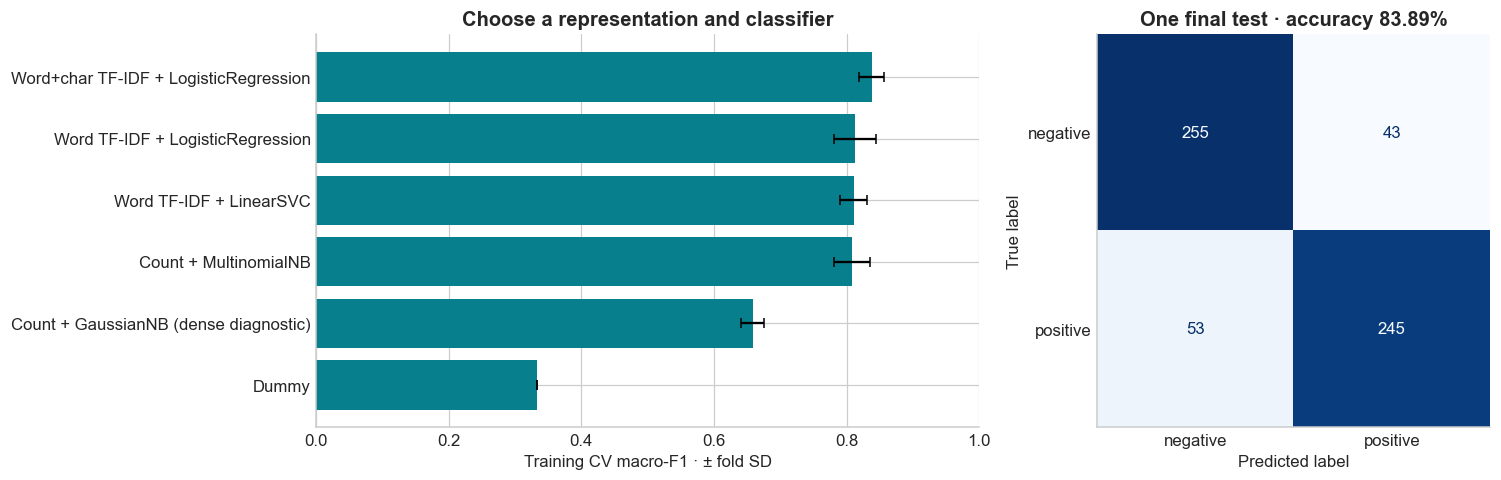

In [8]:
candidates = make_models()
summaries = []
for name, estimator in candidates.items():
    scores = cross_validate(estimator, train.text, train.label, cv=cv, n_jobs=1,
                            scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
                            error_score="raise")
    summaries.append({"model": name, "CV_accuracy": scores["test_accuracy"].mean(),
                      "CV_macro_F1": scores["test_macro_f1"].mean(),
                      "fold_SD": scores["test_macro_f1"].std()})
comparison = pd.DataFrame(summaries).sort_values("CV_macro_F1", ascending=False).reset_index(drop=True)
display(comparison)
selected_name = comparison.iloc[0]["model"]
winner = clone(candidates[selected_name]).fit(train.text, train.label)
prediction = winner.predict(test.text)
test_accuracy = accuracy_score(test.label, prediction)
test_macro_f1 = f1_score(test.label, prediction, average="macro")
matrix = confusion_matrix(test.label, prediction, labels=[0, 1])
print("Selected on training CV:", selected_name)
print(classification_report(test.label, prediction, target_names=["negative", "positive"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
plot = comparison.sort_values("CV_macro_F1")
axes[0].barh(plot.model, plot.CV_macro_F1, xerr=plot.fold_SD, color="#087F8C", capsize=3)
axes[0].set(xlabel="Training CV macro-F1 · ± fold SD", xlim=(0, 1), title="Choose a representation and classifier")
ConfusionMatrixDisplay(matrix, display_labels=["negative", "positive"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].grid(False)
axes[1].set_title(f"One final test · accuracy {test_accuracy:.2%}")
plt.tight_layout()
plt.show()

## Real sparse-memory accounting / Gerçek sparse bellek hesabı

For an $m\times d$ float64 matrix, dense storage is $8md$ bytes. A CSR matrix with `q=nnz`, float64 data and int32 indices uses approximately $8q+4q+4(m+1)$ bytes. Measure the actual NumPy buffer sizes instead of assuming the index dtype. Python object overhead is excluded from both counts.

We fit the word-only model on training data for inspection; it is **not a second test-set model selection step**. An unseen token must not extend the vocabulary during prediction.

**Türkçe:** Büyük matrisi sırf bellek ölçmek için `.toarray()` ile dense yapmıyoruz. Boyut ve dtype üzerinden dense maliyetini, CSR dizilerinin `nbytes` değerleriyle sparse maliyetini hesaplıyoruz.

rows                        2383
columns                     4457
nnz                        32613
density                 0.003071
data_dtype               float64
index_dtype                int32
dense_bytes             84968248
CSR_buffer_bytes          400892
dense_to_CSR_ratio    211.947976
dtype: object

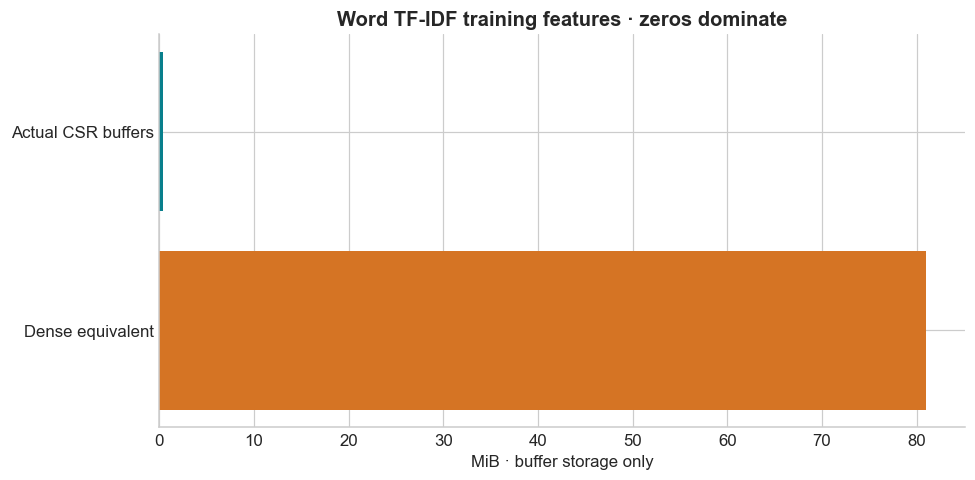

In [9]:
word_model = clone(candidates["Word TF-IDF + LogisticRegression"]).fit(train.text, train.label)
vectorizer = word_model.named_steps["vectorizer"]
word_matrix = vectorizer.transform(train.text).tocsr()
csr_bytes = word_matrix.data.nbytes + word_matrix.indices.nbytes + word_matrix.indptr.nbytes
dense_bytes = int(np.prod(word_matrix.shape) * word_matrix.dtype.itemsize)
density = word_matrix.nnz / np.prod(word_matrix.shape)
vocabulary_before = dict(vectorizer.vocabulary_)
word_model.predict(["zzunseensentinelzz"])
assert vocabulary_before == vectorizer.vocabulary_ and "zzunseensentinelzz" not in vectorizer.vocabulary_
assert sparse.isspmatrix_csr(word_matrix)
display(pd.Series({"rows": word_matrix.shape[0], "columns": word_matrix.shape[1],
                   "nnz": word_matrix.nnz, "density": density,
                   "data_dtype": str(word_matrix.data.dtype), "index_dtype": str(word_matrix.indices.dtype),
                   "dense_bytes": dense_bytes, "CSR_buffer_bytes": csr_bytes,
                   "dense_to_CSR_ratio": dense_bytes / csr_bytes}))
plt.barh(["Dense equivalent", "Actual CSR buffers"], [dense_bytes / 2**20, csr_bytes / 2**20],
         color=["#D57424", "#087F8C"])
plt.xlabel("MiB · buffer storage only")
plt.title("Word TF-IDF training features · zeros dominate")
plt.tight_layout()
plt.show()

## What the linear model learns / Doğrusal model ne öğrenir?

For TF-IDF features, $z=w^\top x+b$ and $P(positive\mid x)=\sigma(z)$. A positive coefficient increases the score **holding other features fixed**. These weights summarize associations in the training reviews; they are not universal language rules. Sparse MultinomialNB instead adds smoothed log word likelihoods to a log class prior.

**Türkçe:** Kelime katsayısı bütün cümlelerden bağımsız bir anlam garantisi değildir. Bağlam, olumsuzluk, ironi ve veri kaynağı sonucu etkiler. `not good` gibi bigramlar, `good` kelimesini tek başına saymaktan farklı kanıt sunar.

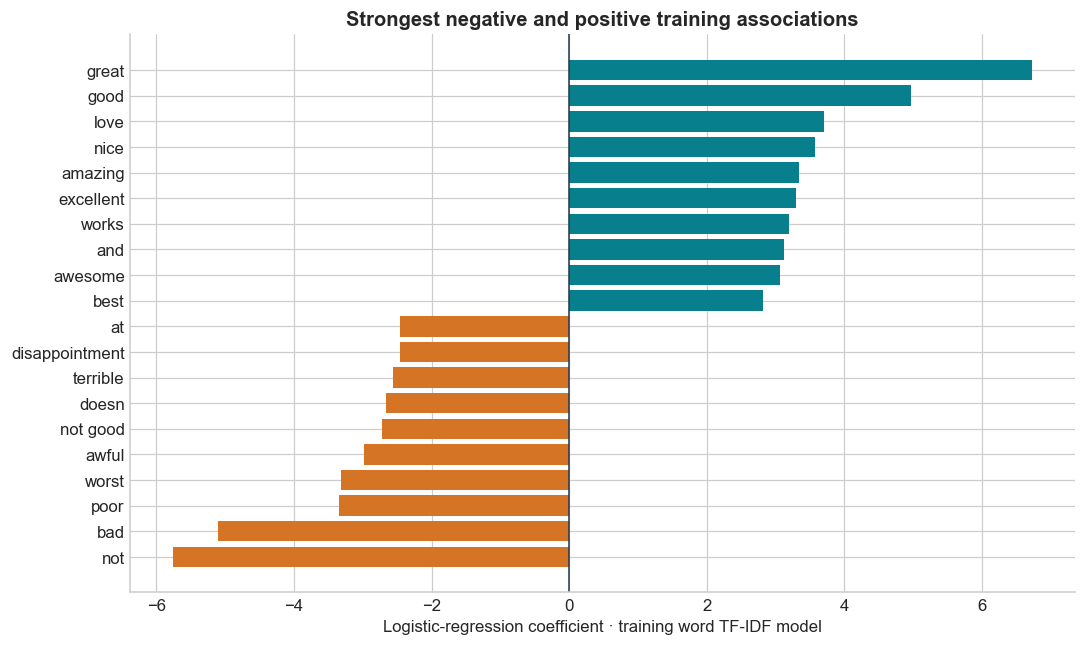

,test_rows,accuracy
source,,
amazon_cells,182.0,0.879121
imdb,192.0,0.770833
yelp,222.0,0.864865


In [10]:
features = vectorizer.get_feature_names_out()
weights = word_model.named_steps["classifier"].coef_[0]
indices = np.r_[np.argsort(weights)[:10], np.argsort(weights)[-10:]]
plt.figure(figsize=(10, 6))
plt.barh(features[indices], weights[indices], color=np.where(weights[indices] < 0, "#D57424", "#087F8C"))
plt.axvline(0, color="#25364A", linewidth=1)
plt.xlabel("Logistic-regression coefficient · training word TF-IDF model")
plt.title("Strongest negative and positive training associations")
plt.tight_layout()
plt.show()
source_results = pd.DataFrame({"source": test.source.to_numpy(), "truth": test.label.to_numpy(),
                               "prediction": prediction})
display(source_results.groupby("source").apply(
    lambda group: pd.Series({"test_rows": len(group), "accuracy": (group.truth == group.prediction).mean()}),
    include_groups=False))

## Why a reported 48% must be audited / Bildirilen %48 neden denetlenmeli?

An accuracy cannot be explained from a number alone. Check parsing and label alignment, split overlap, class balance versus a majority baseline, unsuitable feature distributions, aggressive stopword removal, vocabulary fitting before the split and the exact scoring call. The API is `estimator.score(X_test, y_test)`, not `score(y_test, y_prediction)`. `accuracy_score(y_test, y_prediction)` is a different function.

The small diagnostic below demonstrates the wrong feature shape on a neutral toy task. This is a code/API error, not evidence that a low measured score must have one particular cause. The original 48% has not been reproduced on its original data here.

Improve systematically: retain negation, compare word/character n-grams, choose models with training CV, inspect errors, and evaluate on a new domain/source or time period before claiming broader performance. Never choose changes by repeatedly chasing the same test score.

**Türkçe:** Düşük skoru artırmaya başlamadan önce o skorun doğru ölçüldüğünü doğrulamak gerekir. Bu notebook'un duygu verisindeki başarısı, önceki veri ve hedefe doğrudan taşınamaz.

In [11]:
diagnostic_error = ""
try:
    diagnostic = GaussianNB().fit(np.array([[0, 0, 1], [1, 0, 0], [0, 1, 1], [2, 0, 0]]), [0, 1, 0, 1])
    diagnostic.score(np.array([0, 1]).reshape(-1, 1), [0, 1])
except ValueError as error:
    diagnostic_error = str(error)
print("Expected error from a deliberately malformed score call:", diagnostic_error)
assert "features" in diagnostic_error

Expected error from a deliberately malformed score call: X has 1 features, but GaussianNB is expecting 3 features as input.


## Measured result / Ölçülen sonuç

This summary is produced by the cells above; the runner also collects it in `Classification/notebook_results.json`. A single split is an educational experiment, not a guarantee for a different dataset.

**Türkçe:** Aşağıdaki değerler bu notebook'un gerçek çıktısıdır. Farklı veri veya ayrımlarda aynı sonuç garanti edilmez.

In [12]:
results = {"chapter": 10, "task": "review sentiment; 0=negative, 1=positive",
           "audit": audit, "train_rows": len(train), "test_rows": len(test),
           "selected_by_train_CV": selected_name, "comparison": comparison.to_dict(orient="records"),
           "test_accuracy": float(test_accuracy), "test_macro_f1": float(test_macro_f1),
           "confusion_matrix": matrix.tolist(), "word_TFIDF_shape": list(word_matrix.shape),
           "word_TFIDF_nnz": int(word_matrix.nnz), "dense_bytes": dense_bytes,
           "CSR_buffer_bytes": int(csr_bytes), "vocabulary_unchanged_at_prediction": True}
results["versions"] = versions
display(JSON(results, expanded=True))

<IPython.core.display.JSON object>